In [1]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
!unzip -q -o ml-latest-small.zip
!ls ml-latest-small

links.csv  movies.csv  ratings.csv  README.txt	tags.csv


In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

ratings = pd.read_csv("ml-latest-small/ratings.csv")
movies = pd.read_csv("ml-latest-small/movies.csv")

print(ratings.shape, movies.shape)
display(ratings.head())
display(movies.head())
ratings.info()
print(ratings.isnull().sum())
print("Users:", ratings["userId"].nunique(), " Movies:", ratings["movieId"].nunique())

(100836, 4) (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Users: 610  Movies: 9724


,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


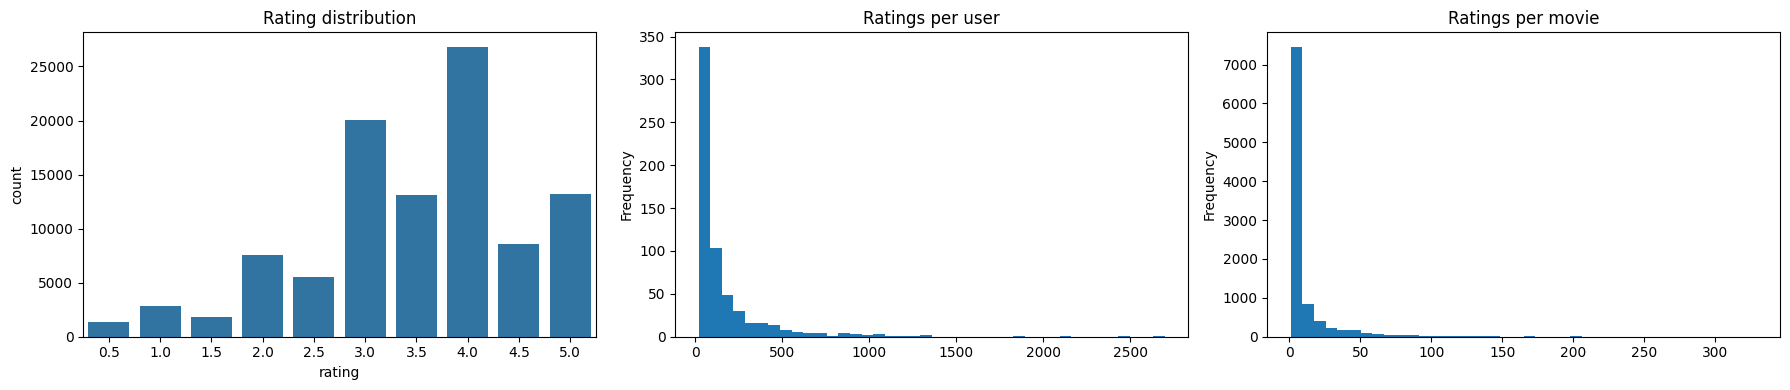

In [3]:
data = ratings.merge(movies, on="movieId")
display(data.head())

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(x="rating", data=data, ax=ax[0]); ax[0].set_title("Rating distribution")
data.groupby("userId").size().plot(kind="hist", bins=40, ax=ax[1])
ax[1].set_title("Ratings per user")
data.groupby("movieId").size().plot(kind="hist", bins=40, ax=ax[2])
ax[2].set_title("Ratings per movie")
plt.tight_layout(); plt.show()

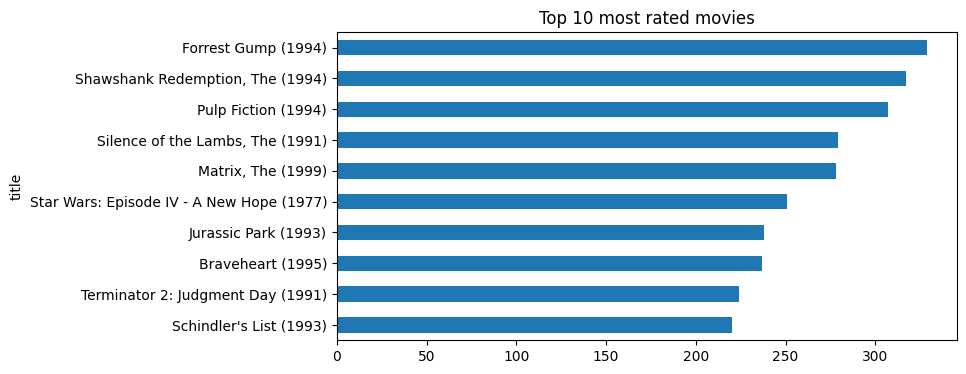

In [4]:
top = data.groupby("title").size().sort_values(ascending=False).head(10)
top.sort_values().plot(kind="barh", figsize=(8, 4), title="Top 10 most rated movies")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

train, test = train_test_split(ratings, test_size=0.2, random_state=42)
train = train.copy()
print(len(train), len(test))

def rmse(y, p): return np.sqrt(mean_squared_error(y, p))

80668 20168


In [6]:
global_mean = train["rating"].mean()

# Baseline 1: sab ke liye average rating
pred_global = np.full(len(test), global_mean)

# Baseline 2: movie ki apni average rating
movie_mean = train.groupby("movieId")["rating"].mean()
pred_movie = test["movieId"].map(movie_mean).fillna(global_mean).values

results = {
    "Global average": (rmse(test["rating"], pred_global), mean_absolute_error(test["rating"], pred_global)),
    "Movie average":  (rmse(test["rating"], pred_movie),  mean_absolute_error(test["rating"], pred_movie)),
}
for k, v in results.items():
    print(f"{k:16s} RMSE={v[0]:.4f}  MAE={v[1]:.4f}")

Global average   RMSE=1.0488  MAE=0.8316
Movie average    RMSE=0.9827  MAE=0.7604


In [7]:
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD

# Index maps
users = np.sort(ratings["userId"].unique())
mov = np.sort(ratings["movieId"].unique())
u_map = {u: i for i, u in enumerate(users)}
m_map = {m: i for i, m in enumerate(mov)}

# Har user ki average rating (sirf train se), phir ratings ko "center" karo
user_mean = train.groupby("userId")["rating"].mean()
user_mean_arr = np.array([user_mean.get(u, global_mean) for u in users])
train["centered"] = train["rating"] - train["userId"].map(user_mean)

rows = train["userId"].map(u_map).values
cols = train["movieId"].map(m_map).values
M = csr_matrix((train["centered"].values, (rows, cols)),
               shape=(len(users), len(mov)))

# Test ke indexes
tu = test["userId"].map(u_map).values
tm = test["movieId"].map(m_map).values

def svd_predict(k):
    svd = TruncatedSVD(n_components=k, random_state=42)
    user_f = svd.fit_transform(M)           # users x k
    item_f = svd.components_.T              # movies x k
    p = user_mean_arr[tu] + np.sum(user_f[tu] * item_f[tm], axis=1)
    return np.clip(p, 0.5, 5.0)

for k in [5, 10, 20, 50]:
    p = svd_predict(k)
    print(f"k={k:3d}  RMSE={rmse(test['rating'], p):.4f}  MAE={mean_absolute_error(test['rating'], p):.4f}")

k=  5  RMSE=0.9219  MAE=0.7117
k= 10  RMSE=0.9210  MAE=0.7104
k= 20  RMSE=0.9229  MAE=0.7117
k= 50  RMSE=0.9320  MAE=0.7193


In [8]:
best_k = 20   # apne output ke mutabiq badlo (sab se kam RMSE wali k)
pred_svd = svd_predict(best_k)
results["SVD (k=%d)" % best_k] = (rmse(test["rating"], pred_svd),
                                  mean_absolute_error(test["rating"], pred_svd))

,RMSE,MAE
Global average,1.0488,0.8316
Movie average,0.9827,0.7604
SVD (k=20),0.9229,0.7117


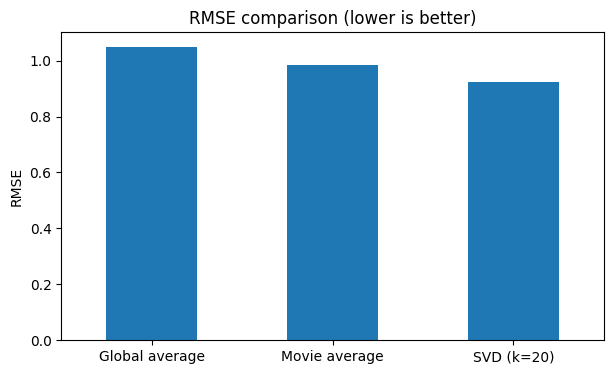

In [9]:
res = pd.DataFrame(results, index=["RMSE", "MAE"]).T.round(4)
display(res)
res["RMSE"].plot(kind="bar", figsize=(7, 4), title="RMSE comparison (lower is better)")
plt.ylabel("RMSE"); plt.xticks(rotation=0); plt.show()

In [10]:
sample = test.copy()
sample["Predicted"] = pred_svd.round(2)
sample = sample.merge(movies[["movieId", "title"]], on="movieId")
sample = sample.rename(columns={"rating": "Actual"})
display(sample[["userId", "title", "Actual", "Predicted"]].head(10))

,userId,title,Actual,Predicted
0,432,Robin Hood (2010),4.5,3.64
1,288,In the Line of Fire (1993),3.0,3.40
2,599,Point Break (1991),3.0,2.68
3,42,Who Framed Roger Rabbit? (1988),4.0,3.77
4,75,"Hunt for Red October, The (1990)",4.0,3.36
5,51,Lord of Illusions (1995),4.0,3.82
6,354,300 (2007),3.5,3.78
7,416,Dr. Strangelove or: How I Learned to Stop Worr...,4.5,3.12
8,438,Charlie's Angels: Full Throttle (2003),0.5,3.16
9,73,Anchorman: The Legend of Ron Burgundy (2004),3.5,3.80


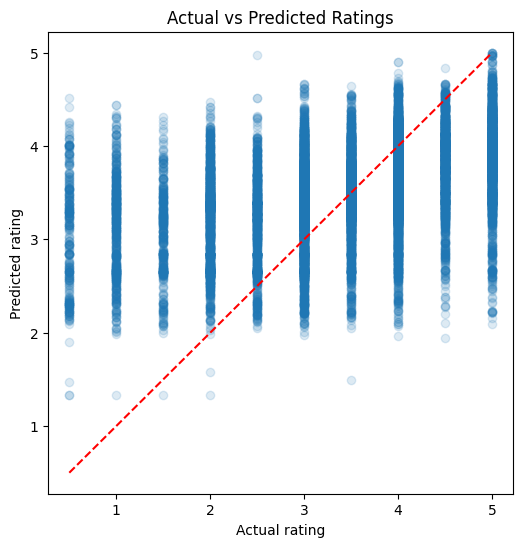

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(test["rating"], pred_svd, alpha=0.15)
plt.plot([0.5, 5], [0.5, 5], "r--")
plt.xlabel("Actual rating"); plt.ylabel("Predicted rating")
plt.title("Actual vs Predicted Ratings"); plt.show()